# EdgeGuard-IoT experiment results

Independent implementation of Jeribi, DOI 10.1016/j.comnet.2026.112813.

The primary real-data experiment completed on 55,645 deduplicated
UNSW-NB15 flows (38,951 train / 16,694 held out).
The raw partition and every deduplicated class count match the paper. The author's
code and frozen split were unavailable, so this is an approximate reproduction.

## Proposed detector

| metric                  |   paper |   this_run |   difference |
|:------------------------|--------:|-----------:|-------------:|
| Accuracy                |  0.8610 |     0.8691 |       0.0081 |
| Weighted F1             |  0.8700 |     0.8756 |       0.0056 |
| Macro F1                |  0.5600 |     0.5702 |       0.0102 |
| MCC                     |  0.7670 |     0.7793 |       0.0123 |
| Mean corrupted macro F1 |  0.3380 |     0.3444 |       0.0064 |

The detector routed 38.8% of held-out flows to stage 2.
Its prediction throughput was 34,383 flows/s on one cloud CPU
core; uncompressed serialized model size was 7.32 MB.
Cloud timings do not establish physical gateway performance or a 4-GB memory budget.

## Baselines

| model        |   accuracy |   macro_f1 |   weighted_f1 |   mean_retained_macro_f1 |
|:-------------|-----------:|-----------:|--------------:|-------------------------:|
| EdgeGuard    |     0.8691 |     0.5702 |        0.8756 |                   0.3444 |
| XGBoost      |     0.8752 |     0.5607 |        0.8799 |                   0.2173 |
| LightGBM     |     0.8777 |     0.5566 |        0.8817 |                   0.2073 |
| RandomForest |     0.8761 |     0.5512 |        0.8792 |                   0.2413 |
| ExtraTrees   |     0.8731 |     0.5430 |        0.8760 |                   0.2727 |
| DecisionTree |     0.8325 |     0.5148 |        0.8455 |                   0.1557 |
| MLP          |     0.7987 |     0.4973 |        0.8216 |                   0.2597 |
| kNN          |     0.8036 |     0.4440 |        0.8202 |                 nan      |
| AdaBoost     |     0.5984 |     0.3760 |        0.6530 |                   0.1396 |
| LogReg       |     0.5288 |     0.3057 |        0.5867 |                   0.2128 |
| LinearSVC    |     0.5143 |     0.2960 |        0.5709 |                   0.1877 |
| HistGBM      |     0.3196 |     0.2277 |        0.3810 |                   0.1040 |
| GaussianNB   |     0.3626 |     0.2081 |        0.4485 |                   0.1785 |

Robustness is the mean absolute macro F1 over 12 seeded corruption conditions.
kNN corruption tests were excluded, following the paper; NaN is unrun, not zero.
The fixed 200-iteration, L2=0 flat HistGBM has an anomalous weak result. A separate
diagnostic records its held-out score trajectory and raw-margin range, and evaluates
L2=1 without replacing the prespecified baseline. No test-score-based iteration
selection is used for the reported baseline. Convergence warnings are saved verbatim
in the corresponding result JSON, rather than treated as convergence.

## Ablations and split sensitivity

| model                         |   accuracy |   macro_f1 |   rare_class_recall |   mean_retained_macro_f1 |
|:------------------------------|-----------:|-----------:|--------------------:|-------------------------:|
| Hierarchical_unbalanced_noaug |     0.8808 |     0.5529 |              0.3279 |                   0.2090 |
| Hierarchical_balanced_noaug   |     0.8740 |     0.5489 |              0.3793 |                   0.2134 |
| Augmented_unbalanced          |     0.8794 |     0.5604 |              0.3605 |                   0.3203 |
| Augmented_weights_only        |     0.8703 |     0.5800 |              0.4878 |                   0.3514 |
| Augmented_SMOTE_only          |     0.8753 |     0.5706 |              0.5529 |                   0.3428 |
| Flat_unbalanced_noaug         |     0.8837 |     0.5729 |              0.3591 |                   0.2165 |
| GroupAware_EdgeGuard          |     0.8700 |     0.5529 |              0.4860 |                   0.3404 |

Rare recall here averages Worms, Backdoor and Shellcode. The paper does not fully
specify this aggregate, so direct comparison of that column is uncertain.
The group-aware experiment rebuilds its split, so it is reported separately from
same-test-set baseline comparisons.

The weighting-only augmented ablation scores 0.5800 macro F1 and 0.3514 retained
macro F1, slightly above the full detector (0.5702 / 0.3444) in this run, while
the full detector gives higher mean recall on the three rarest classes. Thus the
paper's combined design is not uniformly best on every metric here.

## Audit and data-quality findings

All persisted classification metrics were independently recomputed from saved
held-out predictions. Split indices are disjoint, scalers match their training
rows, corruption conditions are complete, and saved models reload successfully.

However, numeric-predictor duplication remains: 394
unique predictor hashes occur on both sides of the primary UNSW split after
numeric-plus-target deduplication. Because identical predictors with different
labels remain separate rows, matching the paper's row count does **not** establish
predictor-level separation. Removing the three categorical fields can also make
different original flows indistinguishable numerically. Edge-IIoTset has
95 shared predictor hashes
on the retained numeric schema. The paper's within-class near-duplicate grouping
does not guarantee separation of identical predictors carrying different labels.
These are explicit limitations of the reproduced protocol; the reported metrics
are not a leakage-free deployment guarantee. A stricter study should group
identical predictors across all labels before splitting and reselect features
within each resulting training split.

## What this does and does not reproduce

Completed: train-only MI/RFE, hierarchy and flat baselines, clean/binary metrics,
corruption sweep, imbalance and component ablations, group-aware split sensitivity,
single-core batch timing, model size, per-stage SHAP, and per-class Friedman/Nemenyi.
Exact hyperparameter/default and augmentation choices are documented in README.md.
Neither similar scores nor a nonsignificant test proves equivalence to the author's
implementation. There is one seeded split, not repeated independent experiments.

## Additional public-data experiments

| condition                                        |   accuracy |   macro_f1 |   paper_macro_f1 |   mean_retained_macro_f1 |
|:-------------------------------------------------|-----------:|-----------:|-----------------:|-------------------------:|
| Edge-IIoTset retraining                          |     0.9396 |     0.9323 |           0.9300 |                   0.5453 |
| Bot-IoT alternative 5% sample (not paper sample) |     0.9833 |     0.9276 |         nan      |                   0.4764 |

Edge-IIoTset matches the paper's 157,800 raw and 152,245 deduplicated rows.
There are 34 globally variable numeric predictors; train-only constant detection
retains 33 for this split. Independent MI/RFE retains twenty of them.

The five-feature UNSW-to-Bot-IoT transfer flagged 11.04%
of 1,000,000 genuine DoS flows as attacks (paper: 7.3%). Its own
in-domain Stage-1 F1 was 0.8662 and attack recall was
0.8770. This is attack recall on an
attack-only dataset, **not multiclass macro F1**. It supports severe domain shift,
without claiming numerical identity to the paper's result.

The original forty-scenario-file Bot-IoT sample was not located in the public
sources checked. Its claimed 136,039-row same-dataset result is **not reproduced**.
The alternative Bot-IoT sample uses the four-file 5% release, all benign/Theft rows,
and up to 3,000 random rows per other category per file. It has 18,556 sampled
rows before deduplication and 16,330 afterwards, five classes, fifteen numeric
features; its smaller benign class makes direct comparison inappropriate. The
full sample manifest is included. No synthetic data stand in for any benchmark.

Public GitHub mirrors enabled these experiments despite proxy errors from the
university, IEEE DataPort, Kaggle and UNSW SharePoint sources. The data mirrors
are pinned to commits and hashes, but no independent original-source checksum
was available. No matching public author implementation was located; the similarly
named `raaddi/edgeguard-iot` repository is an unrelated SmartHome project.

Source code, dependency lock, per-class scores, corruption scores and the detailed
protocol are included. Raw benchmark data and trained model binaries remain in the
cloud workspace and are excluded from this shareable report bundle.


,model,accuracy,macro_f1,weighted_f1,mcc,rare_class_recall,throughput_flows_s,batch_amortized_ms_flow,inference_pass_seconds,serialized_bytes,...,stage2_smote_counts,mean_retained_macro_f1,performance_retention_ratio,fit_seconds,fit_warnings,sample_weight_supported,robustness_status,train_rows,test_rows,max_class_test_fraction_deviation
0,EdgeGuard,0.869055,0.570241,0.875596,0.779282,0.577590,3.438260e+04,0.029084,"[0.49620482399996035, 0.4784379729999273, 0.47...",7320194,...,"{0: 4000, 1: 4000, 2: 4000, 3: 5283, 4: 4000, ...",0.344417,0.603985,21.253256,[],True,NaN,NaN,NaN,NaN
1,HistGBM,0.319576,0.227712,0.381010,0.216089,0.369079,1.207661e+04,0.082805,"[1.4259369080000397, 1.4178143159999763, 1.382...",7172464,...,NaN,0.103968,0.456578,14.594168,[],True,NaN,NaN,NaN,NaN
2,XGBoost,0.875225,0.560694,0.879862,0.790272,0.425169,2.094980e+04,0.047733,"[0.7037114809998002, 0.7968574280000666, 0.905...",12654361,...,NaN,0.217306,0.387567,18.657653,[],True,NaN,NaN,NaN,NaN
3,LightGBM,0.877681,0.556599,0.881652,0.793601,0.369032,5.423083e+03,0.184397,"[2.920667117999983, 3.1507899250000264, 3.0783...",13293636,...,NaN,0.207261,0.372370,15.264599,[],True,NaN,NaN,NaN,NaN
4,RandomForest,0.876063,0.551189,0.879188,0.787831,0.421221,8.654963e+04,0.011554,"[0.19288355800017598, 0.19243057900007443, 0.1...",173670729,...,NaN,0.241282,0.437749,11.702650,[],True,NaN,NaN,NaN,NaN
5,ExtraTrees,0.873068,0.543011,0.875955,0.782460,0.431544,5.911076e+04,0.016917,"[0.2836769919999824, 0.28692541999998866, 0.28...",494300697,...,NaN,0.272711,0.502221,4.316375,[],True,NaN,NaN,NaN,NaN
6,DecisionTree,0.832455,0.514765,0.845485,0.726156,0.410330,8.953684e+06,0.000112,"[0.0018644839999524265, 0.0018849850000606239,...",1241369,...,NaN,0.155665,0.302401,0.836874,[],True,NaN,NaN,NaN,NaN
7,MLP,0.798730,0.497340,0.821553,0.686121,0.614787,1.392157e+06,0.000718,"[0.01153590300009455, 0.01199146500016468, 0.0...",181920,...,NaN,0.259686,0.522150,12.552222,[],True,NaN,NaN,NaN,NaN
8,kNN,0.803582,0.443954,0.820229,0.671821,0.343866,5.123505e+03,0.195179,"[3.2583164549998855, 3.1170854169999984, 3.327...",10286676,...,NaN,NaN,NaN,0.004007,[],False,not run: kNN excluded as in paper,NaN,NaN,NaN
9,AdaBoost,0.598359,0.376042,0.652988,0.472762,0.324827,4.346160e+05,0.002301,"[0.038410921000149756, 0.03886389999979656, 0....",46276,...,NaN,0.139624,0.371299,4.486266,[],True,NaN,NaN,NaN,NaN


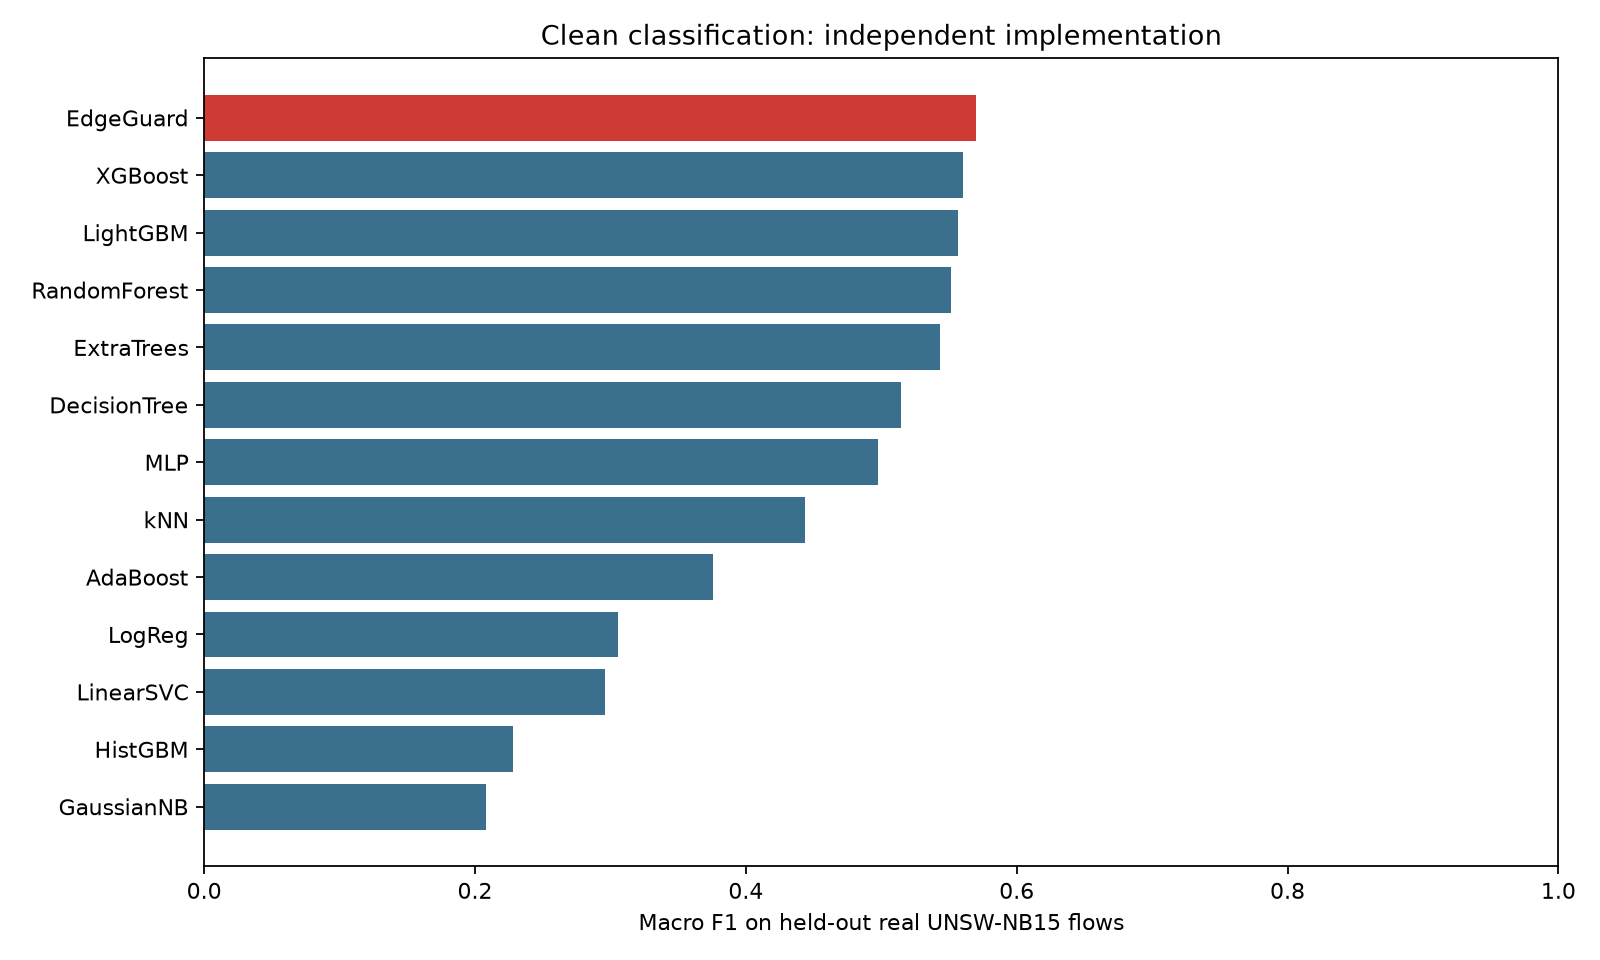

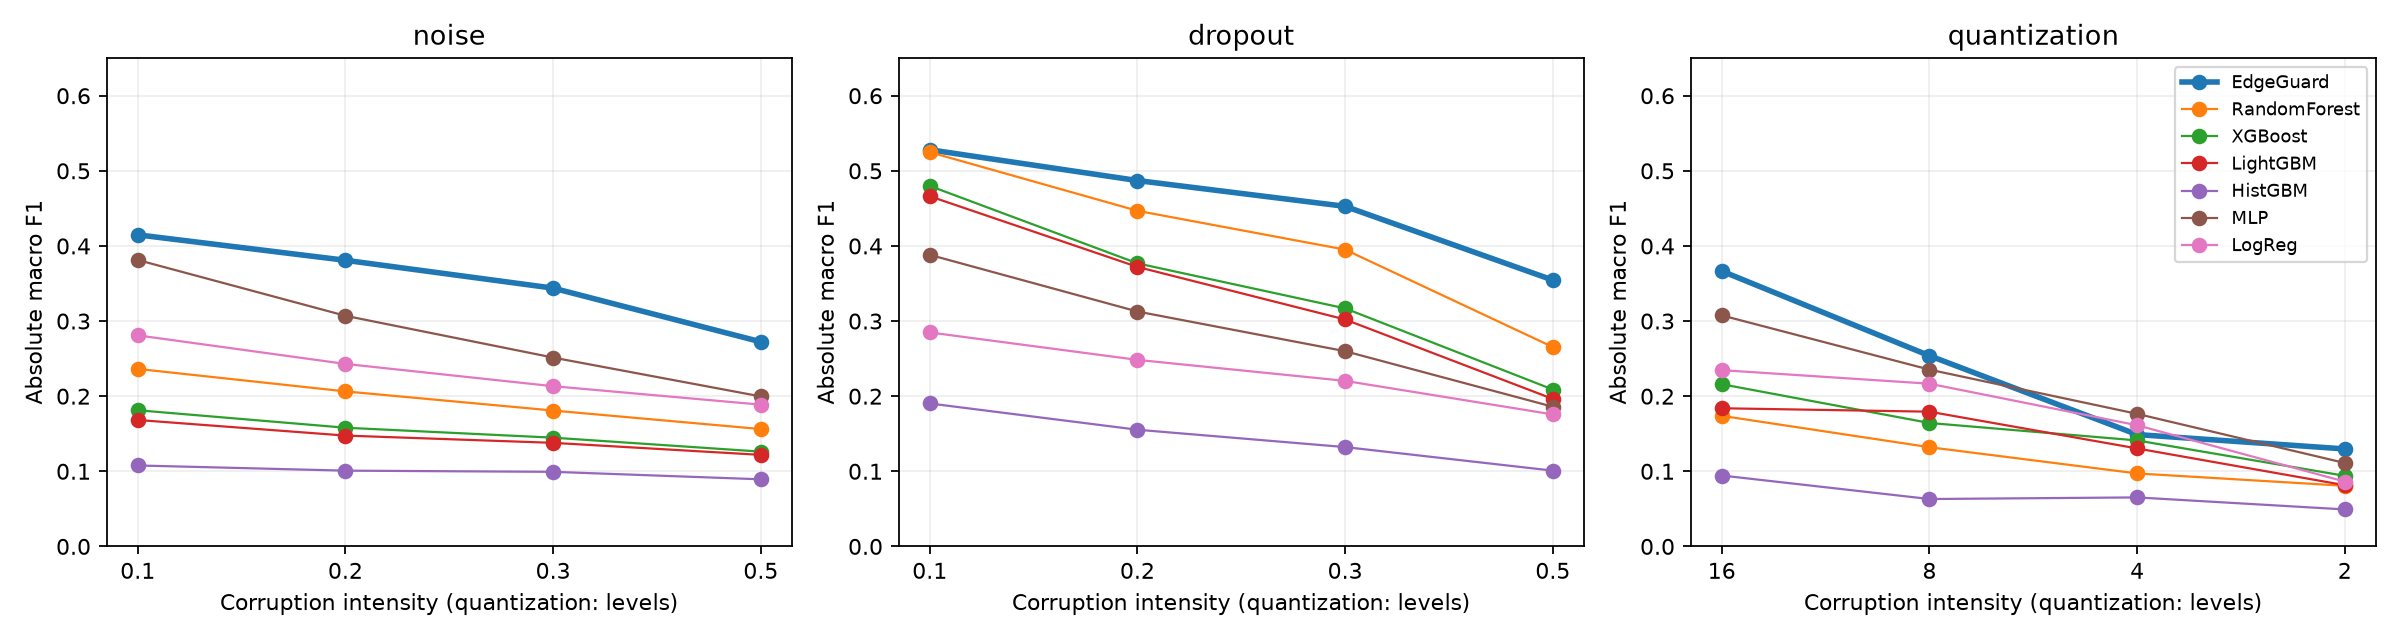

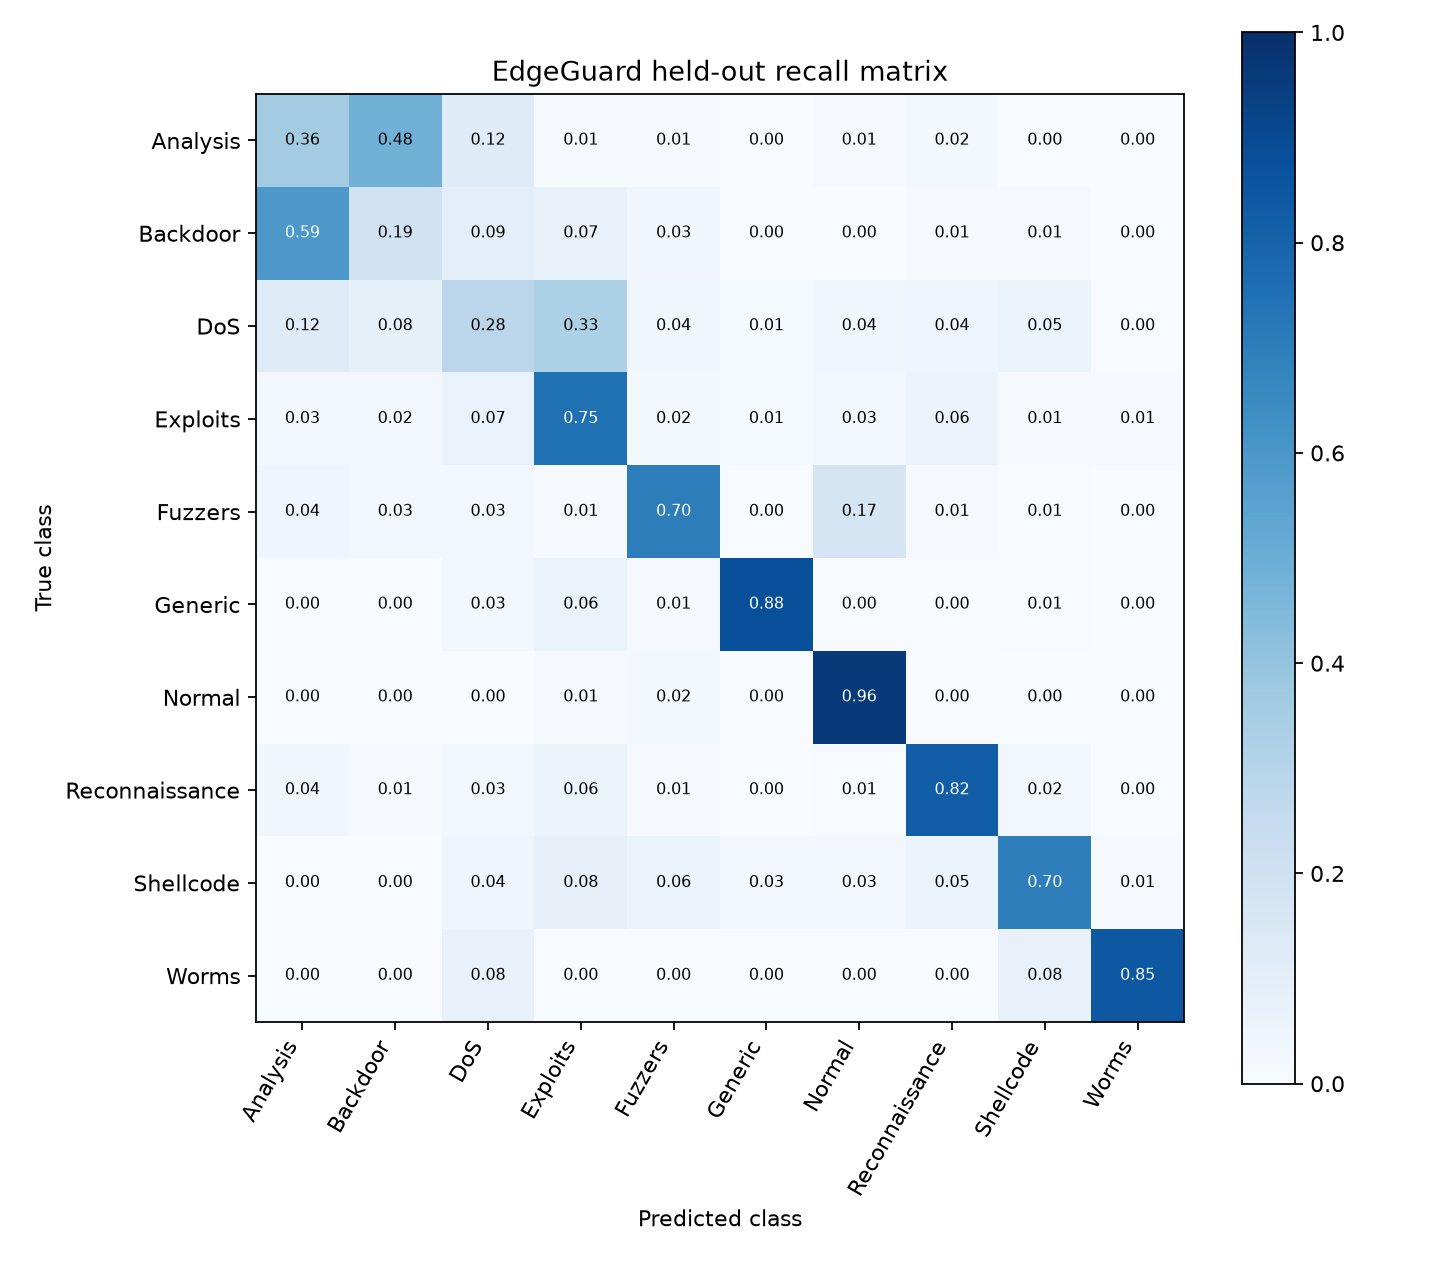

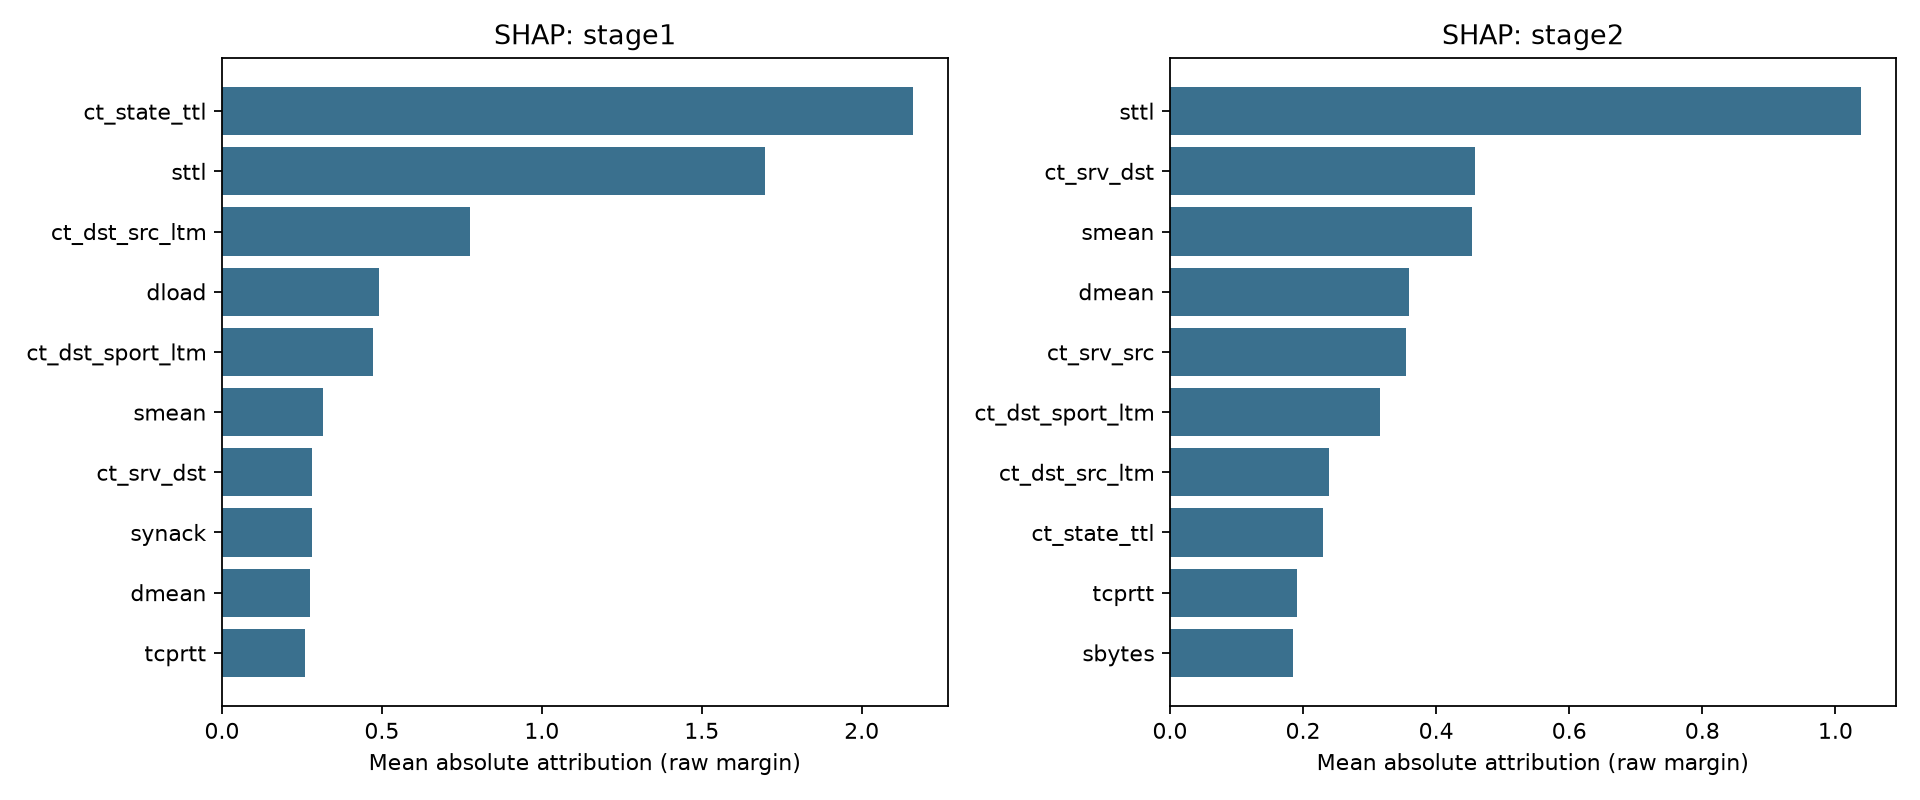

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / 'results/summary.csv'))
for name in ['clean_comparison', 'robustness', 'confusion_matrix', 'shap']:
    display(Image(filename=str(root / 'figures' / (name + '.png'))))